In [4]:
%load_ext autoreload
%autoreload 2

import os

os.environ["DSDIR"] = "/work3/projects/HAC-DTU"

from hac.data import get_model_stl_path
from hac.mitsuba import make_interactive_layout, MitsubaMesh, RenderingSettings
from hac.constants import OBSERVERS, MODEL_BASE_RADII
import mitsuba as mi


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
mi.set_variant("cuda_ad_mono")

MODEL_NUM = 3
N_PHASES = 4

mesh_stl_path = get_model_stl_path(MODEL_NUM)
mesh = MitsubaMesh.from_stl_path(mesh_stl_path)

rendering_settings = RenderingSettings(
    width=64,
    height=64,
    spp=8,
)

bounding_cylinder_radius = MODEL_BASE_RADII[MODEL_NUM]

figure = make_interactive_layout(
    mesh,
    N_PHASES,
    OBSERVERS,
    rendering_settings,
    bounding_cylinder_radius,
    normalize_mesh=True,
    mesh_face_target=10_000,
)
# figure.show()

# Opens a browser tab
figure.show(renderer="browser")

(node:1867322) [DEP0169] DeprecationWarning: `url.parse()` behavior is not standardized and prone to errors that have security implications. Use the WHATWG URL API instead. CVEs are not issued for `url.parse()` vulnerabilities.
(Use `node --trace-deprecation ...` to show where the warning was created)


Ellipsis

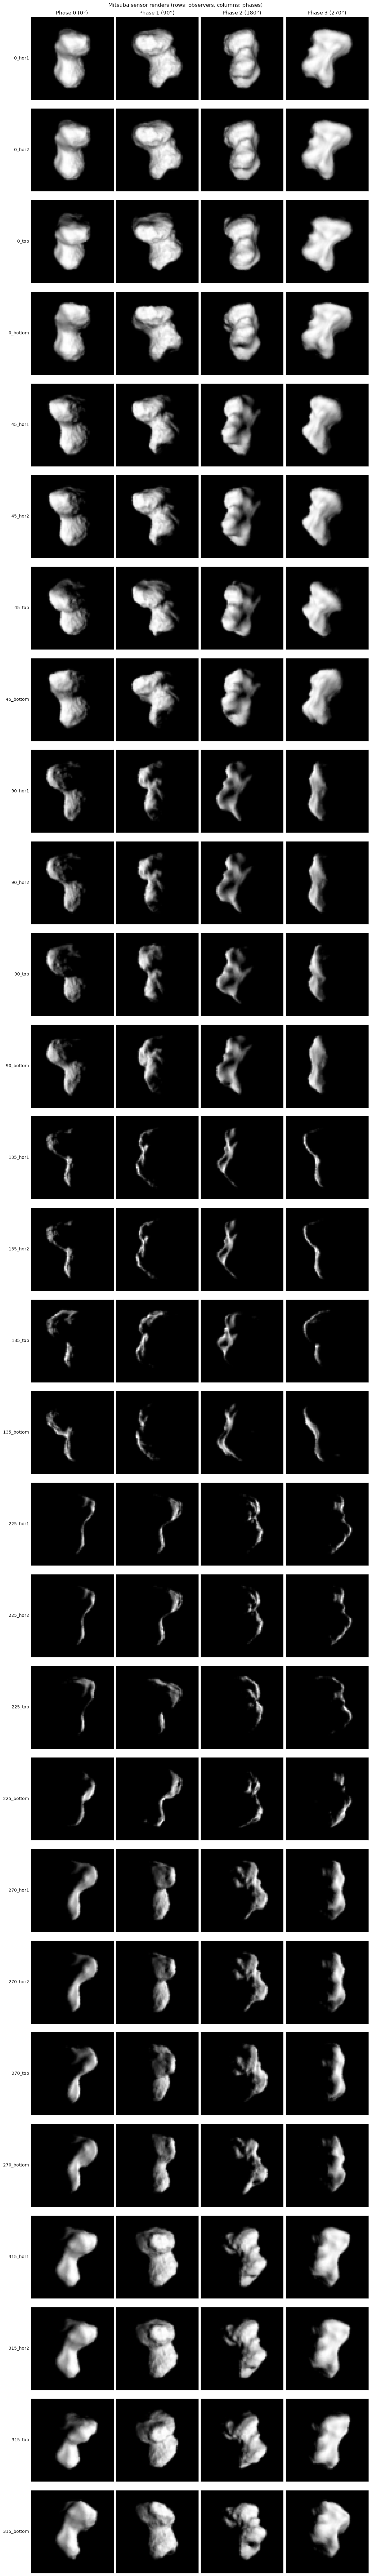

In [6]:
from hac.mitsuba import make_mitsuba_render_grid

make_mitsuba_render_grid(
    mesh,
    N_PHASES,
    OBSERVERS,
    rendering_settings,
    bounding_cylinder_radius,
    normalize_mesh=True,
)
...